Loading I-JEPA ViT-H/14...


config.json:   0%|          | 0.00/497 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.52GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/325 [00:00<?, ?B/s]

Model loaded!



100%|██████████| 169M/169M [01:10<00:00, 2.40MB/s]


Embedding 200 images with I-JEPA...
  20/200 done (85s elapsed, ~761s remaining)
  40/200 done (169s elapsed, ~676s remaining)
  60/200 done (258s elapsed, ~601s remaining)
  80/200 done (344s elapsed, ~515s remaining)
  100/200 done (431s elapsed, ~431s remaining)
  120/200 done (518s elapsed, ~346s remaining)
  140/200 done (603s elapsed, ~259s remaining)
  160/200 done (689s elapsed, ~172s remaining)
  180/200 done (775s elapsed, ~86s remaining)
  200/200 done (866s elapsed, ~0s remaining)

Embedding matrix: torch.Size([200, 1280])
Total time: 866s
Embedding norms: min=18.7, max=30.2, mean=23.3

Cosine similarity stats (off-diagonal):
  Min: 0.2589
  Max: 0.9573
  Mean: 0.6812
  Std: 0.1062

RUNNING MASTER EQUATION
N=200, T=3000, β=3.0, γ=0.2, δ=0.1
Embeddings: Real I-JEPA 1280-d, NORMALIZED

Simulating...
  Step 500: 0/200 alive, max=0.0000, mean=0.0000
  Step 1000: 0/200 alive, max=0.0001, mean=0.0001
  Step 1500: 0/200 alive, max=0.0001, mean=0.0001
  Step 2000: 0/200 alive, max=

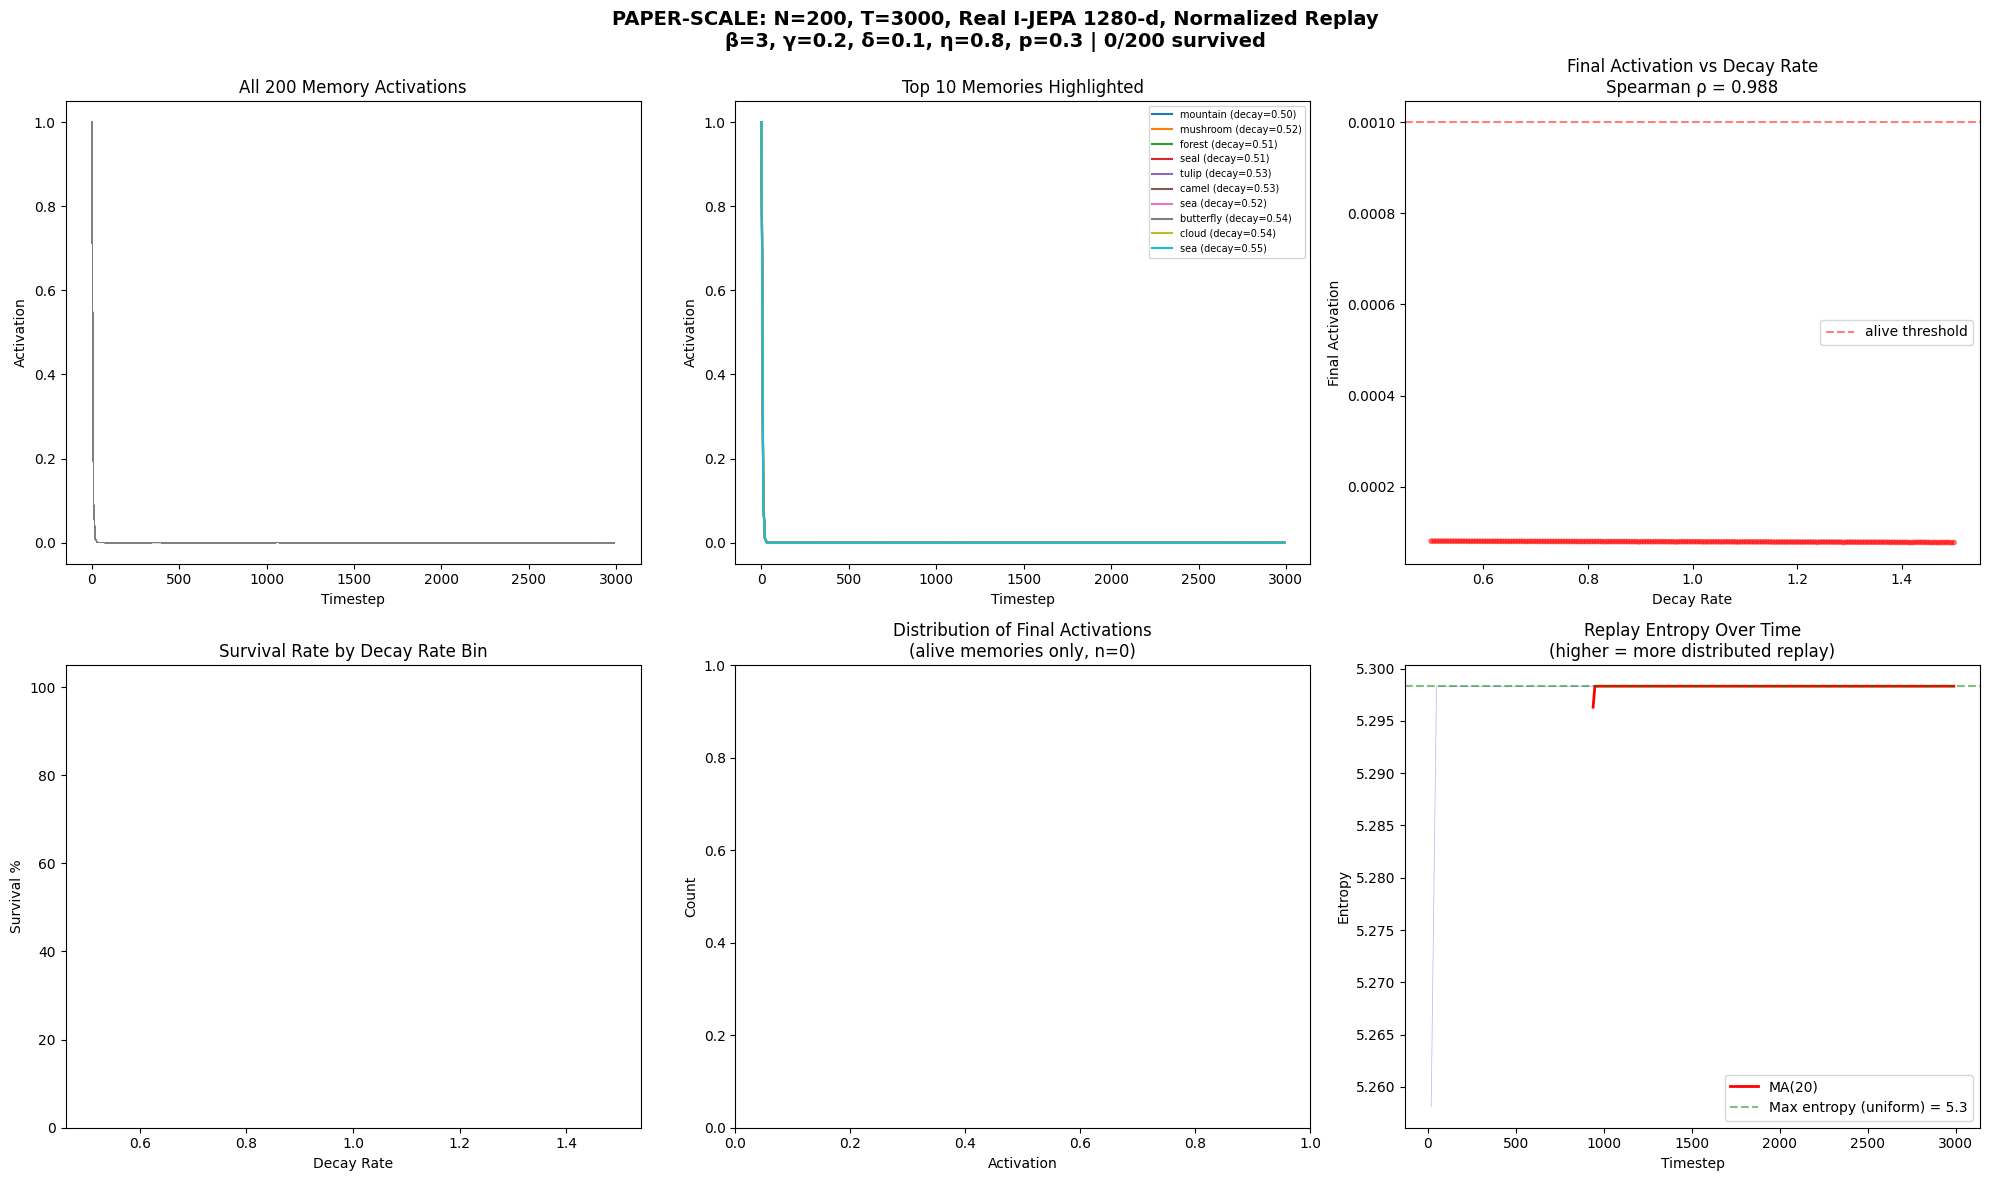


COMPARISON WITH PAPER'S CLAIMS

Paper's setup:     N=200, d=64, Gaussian random vectors, unnormalized, β=3
Paper's result:    Balanced regime — memories survive based on decay rate

Our setup:         N=200, d=1280, Real I-JEPA embeddings, NORMALIZED, β=3
Our result:        0/200 survived, Spearman ρ = 0.988

Does the balanced regime hold with real embeddings?
YES — decay rate predicts survival/ranking

Key difference from paper:
  Paper's Gaussian vectors are approximately orthogonal (low similarity)
  Real I-JEPA embeddings have STRUCTURE (some images are genuinely similar)
  This means diffusion (similarity-based spreading) plays a bigger role



In [1]:
"""
PAPER-SCALE EXPERIMENT WITH REAL I-JEPA EMBEDDINGS
====================================================
N=200 memories, T=3000 steps, β=3, γ=0.2, δ=0.1
Real I-JEPA ViT-H/14 embeddings (1280-d) + NORMALIZED replay

Images: 200 images from CIFAR-100 test set (no 404s, all local)
"""

import torch
import numpy as np
import matplotlib.pyplot as plt
from transformers import AutoModel, AutoProcessor
from PIL import Image
import torchvision
import torchvision.transforms as transforms
import time

# ============================================================
# 1. LOAD I-JEPA MODEL
# ============================================================
print("Loading I-JEPA ViT-H/14...")
model = AutoModel.from_pretrained("facebook/ijepa_vith14_1k")
processor = AutoProcessor.from_pretrained("facebook/ijepa_vith14_1k")
model.eval()
print("Model loaded!\n")

# ============================================================
# 2. GET 200 REAL IMAGES FROM CIFAR-100
# ============================================================
print("Downloading CIFAR-100 test set...")
cifar100 = torchvision.datasets.CIFAR100(
    root='./data', train=False, download=True
)

# Pick first 200 images (diverse classes)
N = 200
print(f"Embedding {N} images with I-JEPA...")

embeddings = []
labels = []
batch_size = 10

start_time = time.time()
for i in range(N):
    img, label_idx = cifar100[i]
    # CIFAR images are 32x32 PIL, I-JEPA expects larger but handles it
    # Resize to 224x224 for ViT
    img = img.resize((224, 224), Image.BILINEAR)

    inputs = processor(images=img, return_tensors="pt")
    with torch.no_grad():
        outputs = model(**inputs)
    emb = outputs.last_hidden_state.mean(dim=1).squeeze()  # 1280-d, same as your notebook
    embeddings.append(emb)
    labels.append(cifar100.classes[label_idx])

    if (i + 1) % 20 == 0:
        elapsed = time.time() - start_time
        rate = (i + 1) / elapsed
        remaining = (N - i - 1) / rate
        print(f"  {i+1}/{N} done ({elapsed:.0f}s elapsed, ~{remaining:.0f}s remaining)")

X = torch.stack(embeddings)
print(f"\nEmbedding matrix: {X.shape}")  # Should be [200, 1280]
print(f"Total time: {time.time() - start_time:.0f}s")

# Check norms
norms = X.norm(dim=1)
print(f"Embedding norms: min={norms.min():.1f}, max={norms.max():.1f}, mean={norms.mean():.1f}")

# ============================================================
# 3. NORMALIZE EMBEDDINGS
# ============================================================
X_norm = X / X.norm(dim=1, keepdim=True)

# Verify: cosine similarity stats
cos_sim = X_norm @ X_norm.T
# Zero diagonal for stats
mask = ~torch.eye(N, dtype=bool)
off_diag = cos_sim[mask]
print(f"\nCosine similarity stats (off-diagonal):")
print(f"  Min: {off_diag.min():.4f}")
print(f"  Max: {off_diag.max():.4f}")
print(f"  Mean: {off_diag.mean():.4f}")
print(f"  Std: {off_diag.std():.4f}")

# ============================================================
# 4. RUN MASTER EQUATION — PAPER'S EXACT PARAMETERS
# ============================================================
print("\n" + "="*60)
print("RUNNING MASTER EQUATION")
print(f"N={N}, T=3000, β=3.0, γ=0.2, δ=0.1")
print("Embeddings: Real I-JEPA 1280-d, NORMALIZED")
print("="*60)

# Parameters (paper's exact values)
T = 3000
dt = 0.01
beta = 3.0
gamma = 0.2
delta = 0.1
eta = 0.8
p = 0.3
seed = 42

torch.manual_seed(seed)
np.random.seed(seed)

# Decay rates: linearly spaced like paper
A = torch.linspace(0.5, 1.5, N)

# Similarity and Laplacian (using normalized embeddings)
S = X_norm @ X_norm.T
W = S.clone()
W.fill_diagonal_(0)
D_mat = torch.diag(W.sum(dim=1))
L = D_mat - W

# Initial activations
activations = torch.ones(N)

# Track history (sample every 10 steps to save memory)
sample_interval = 10
history = np.zeros((N, T // sample_interval))
replay_entropy_history = []

print("\nSimulating...")
sim_start = time.time()

for t in range(T):
    # Record
    if t % sample_interval == 0:
        history[:, t // sample_interval] = activations.numpy()

    a = activations

    # 1. Decay
    decay = -A * a

    # 2. Diffusion
    diffusion = -gamma * (L @ a)

    # 3. Inhibition
    inhibition = -delta * a.sum() * torch.ones(N)

    # 4. Replay (normalized)
    stim = (torch.rand(1).item() < p)
    if stim:
        scores = X_norm @ X_norm.T @ a
        replay_weights = torch.softmax(beta * scores, dim=0)
        replay = eta * replay_weights

        # Track replay entropy (how spread out is replay?)
        entropy = -(replay_weights * torch.log(replay_weights + 1e-10)).sum().item()
        if t % sample_interval == 0:
            replay_entropy_history.append(entropy)
    else:
        replay = torch.zeros(N)
        if t % sample_interval == 0:
            replay_entropy_history.append(None)

    # Update
    da = decay + diffusion + inhibition + replay
    activations = torch.clamp(a + dt * da, min=0)

    if (t + 1) % 500 == 0:
        alive = (activations > 0.001).sum().item()
        top_act = activations.max().item()
        print(f"  Step {t+1}: {alive}/{N} alive, max={top_act:.4f}, mean={activations.mean():.4f}")

sim_time = time.time() - sim_start
print(f"\nSimulation done in {sim_time:.1f}s")

# ============================================================
# 5. ANALYSIS
# ============================================================
final_a = activations.numpy()
alive_mask = final_a > 0.001
n_alive = alive_mask.sum()
n_dead = N - n_alive

print("\n" + "="*60)
print("RESULTS")
print("="*60)
print(f"Survivors (a > 0.001): {n_alive}/{N} ({n_alive/N*100:.1f}%)")
print(f"Dead (a ≤ 0.001): {n_dead}/{N} ({n_dead/N*100:.1f}%)")
print(f"Max activation: {final_a.max():.6f}")
print(f"Min (alive): {final_a[alive_mask].min():.6f}" if n_alive > 0 else "No survivors")
print(f"Mean (alive): {final_a[alive_mask].mean():.6f}" if n_alive > 0 else "")
print(f"Mean (all): {final_a.mean():.6f}")

# Check decay ranking
sorted_by_decay = np.argsort(A.numpy())  # lowest decay first
sorted_by_activation = np.argsort(-final_a)  # highest activation first

# Rank correlation
from scipy.stats import spearmanr
rho, pval = spearmanr(A.numpy(), -final_a)
print(f"\nDecay-Activation rank correlation (Spearman ρ): {rho:.4f} (p={pval:.2e})")
print("(ρ close to 1.0 means lowest decay → highest activation, as paper predicts)")

# Top 10 and bottom 10
print(f"\nTop 10 memories (highest activation):")
print(f"  {'Rank':<6} {'Label':<20} {'Decay':<10} {'Activation':<12}")
for rank, idx in enumerate(sorted_by_activation[:10]):
    print(f"  {rank+1:<6} {labels[idx]:<20} {A[idx]:.4f}    {final_a[idx]:.6f}")

print(f"\nBottom 10 memories (lowest activation, still alive):")
alive_sorted = sorted_by_activation[sorted_by_activation < N]
for rank, idx in enumerate(alive_sorted[-10:][::-1]):
    if final_a[idx] > 0.001:
        print(f"  {N-rank:<6} {labels[idx]:<20} {A[idx]:.4f}    {final_a[idx]:.6f}")

# ============================================================
# 6. PLOTS
# ============================================================
fig, axes = plt.subplots(2, 3, figsize=(20, 12))
fig.suptitle(f"PAPER-SCALE: N={N}, T=3000, Real I-JEPA 1280-d, Normalized Replay\n"
             f"β=3, γ=0.2, δ=0.1, η=0.8, p=0.3 | {n_alive}/{N} survived",
             fontsize=14, fontweight='bold')

timesteps = np.arange(0, T, sample_interval)

# Plot 1: All activation curves
ax = axes[0, 0]
for i in range(N):
    alpha = 0.3 if final_a[i] < 0.001 else 0.8
    color = 'gray' if final_a[i] < 0.001 else None
    ax.plot(timesteps, history[i, :], alpha=alpha, linewidth=0.5, color=color)
ax.set_title(f"All {N} Memory Activations")
ax.set_xlabel("Timestep")
ax.set_ylabel("Activation")

# Plot 2: Top 10 memories highlighted
ax = axes[0, 1]
for i in range(N):
    ax.plot(timesteps, history[i, :], alpha=0.1, linewidth=0.3, color='gray')
for rank, idx in enumerate(sorted_by_activation[:10]):
    ax.plot(timesteps, history[idx, :], linewidth=1.5,
            label=f"{labels[idx]} (decay={A[idx]:.2f})")
ax.set_title("Top 10 Memories Highlighted")
ax.set_xlabel("Timestep")
ax.set_ylabel("Activation")
ax.legend(fontsize=7, loc='upper right')

# Plot 3: Final activation vs decay rate
ax = axes[0, 2]
colors = ['green' if a > 0.001 else 'red' for a in final_a]
ax.scatter(A.numpy(), final_a, c=colors, alpha=0.5, s=10)
ax.set_title(f"Final Activation vs Decay Rate\nSpearman ρ = {rho:.3f}")
ax.set_xlabel("Decay Rate")
ax.set_ylabel("Final Activation")
ax.axhline(y=0.001, color='red', linestyle='--', alpha=0.5, label='alive threshold')
ax.legend()

# Plot 4: Survival by decay rate (binned)
ax = axes[1, 0]
n_bins = 10
decay_bins = np.linspace(0.5, 1.5, n_bins + 1)
survival_rates = []
bin_centers = []
for b in range(n_bins):
    mask = (A.numpy() >= decay_bins[b]) & (A.numpy() < decay_bins[b+1])
    if mask.sum() > 0:
        survived = (final_a[mask] > 0.001).sum() / mask.sum() * 100
        survival_rates.append(survived)
        bin_centers.append((decay_bins[b] + decay_bins[b+1]) / 2)
ax.bar(bin_centers, survival_rates, width=0.08, color='steelblue', alpha=0.8)
ax.set_title("Survival Rate by Decay Rate Bin")
ax.set_xlabel("Decay Rate")
ax.set_ylabel("Survival %")
ax.set_ylim(0, 105)

# Plot 5: Activation distribution (histogram)
ax = axes[1, 1]
alive_activations = final_a[final_a > 0.001]
if len(alive_activations) > 0:
    ax.hist(alive_activations, bins=30, color='steelblue', alpha=0.8, edgecolor='black')
ax.set_title(f"Distribution of Final Activations\n(alive memories only, n={n_alive})")
ax.set_xlabel("Activation")
ax.set_ylabel("Count")

# Plot 6: Replay entropy over time
ax = axes[1, 2]
valid_entropy = [(t, e) for t, e in zip(timesteps, replay_entropy_history) if e is not None]
if valid_entropy:
    ent_t, ent_v = zip(*valid_entropy)
    ax.plot(ent_t, ent_v, alpha=0.3, linewidth=0.5, color='blue')
    # Moving average
    window = 20
    if len(ent_v) > window:
        ent_arr = np.array(ent_v)
        ma = np.convolve(ent_arr, np.ones(window)/window, mode='valid')
        ax.plot(np.array(ent_t)[window-1:], ma, color='red', linewidth=2, label=f'MA({window})')
    ax.set_title("Replay Entropy Over Time\n(higher = more distributed replay)")
    ax.set_xlabel("Timestep")
    ax.set_ylabel("Entropy")
    max_entropy = np.log(N)
    ax.axhline(y=max_entropy, color='green', linestyle='--', alpha=0.5,
               label=f'Max entropy (uniform) = {max_entropy:.1f}')
    ax.legend()

plt.tight_layout()
plt.savefig("paper_scale_real_jepa.png", dpi=150, bbox_inches='tight')
plt.show()

print("\n" + "="*60)
print("COMPARISON WITH PAPER'S CLAIMS")
print("="*60)
print(f"""
Paper's setup:     N=200, d=64, Gaussian random vectors, unnormalized, β=3
Paper's result:    Balanced regime — memories survive based on decay rate

Our setup:         N=200, d=1280, Real I-JEPA embeddings, NORMALIZED, β=3
Our result:        {n_alive}/{N} survived, Spearman ρ = {rho:.3f}

Does the balanced regime hold with real embeddings?
{'YES — decay rate predicts survival/ranking' if rho > 0.5 else 'PARTIALLY — some correlation but not perfect'}

Key difference from paper:
  Paper's Gaussian vectors are approximately orthogonal (low similarity)
  Real I-JEPA embeddings have STRUCTURE (some images are genuinely similar)
  This means diffusion (similarity-based spreading) plays a bigger role
""")